# Figures A1 and A2: closed-form min-norm solutions, linear and ReLU random features

Final camera-ready version. Both figures are drawn from the archived sweep `results_pinv_linear_and_relu_20260428_181712.pkl` (output of the experiment code at the end of this notebook: $(\alpha_1,\alpha_2)=(1.0,0.3)$, 20 seeds, $N$-sweep at $D=50{,}000$, $D$-sweep at $N=16{,}000$). Nothing is recomputed here. The fits reproduce the captions: A1 (linear) shared $\alpha = 1.999$, sparse $\alpha_D = 1.114$; A2 (ReLU) $\alpha = 1.249$, $\alpha_D = 1.104$. As in the paper, A1 drops the numerical outlier $N=384$ and restricts the sparse $N$-sweep to $N \le 256$.

Both keep the original $8\times7$ in canvas; LaTeX places them at `0.525\textwidth` (2.89 in), a scale of about 0.345, and the source font sizes are chosen so they print at: tick labels 7 pt, axis labels 8 pt, row labels 9 pt. Other changes from the submitted version, as for Figure 4: no $\ell$ label on the right-hand panels, vertical gap 0.7 (was 0.55), one labelled tick per decade; and the crowded top tick label is dropped in A1's dense panels ($10^{-1}$ left, $10^{-2}$ right) and in A2's dense $D$ panel ($10^{-1}$).

In [ ]:
import pickle
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Printed font sizes: LaTeX scales these figures by PRINT_SCALE (2.89 in / PDF width)
PRINT_SCALE = 0.3446
FA_TICK, FA_LABEL, FA_ROW = 7 / PRINT_SCALE, 8 / PRINT_SCALE, 9 / PRINT_SCALE

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42,
    "font.size": 11,
    "axes.labelsize": FA_LABEL,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": FA_TICK,
    "ytick.labelsize": FA_TICK,
    "axes.linewidth": 0.8,
})


@dataclass
class Config:          # needed to unpickle the archived results
    alpha1: float = 1.0
    alpha2: float = 0.3
    M: int = 10_000
    n_test: int = 50_000
    n_seeds: int = 20


In [ ]:
import numpy as np

def fit_powerlaw(xs, ys, tail=None):
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if tail is not None:
        xs, ys = xs[-tail:], ys[-tail:]
    lx, ly = np.log(xs), np.log(ys)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coeffs, *_ = np.linalg.lstsq(A, ly, rcond=None)
    return -float(coeffs[0]), float(coeffs[1])


In [ ]:
RESULTS = "results_pinv_linear_and_relu_20260428_181712.pkl"
with open(RESULTS, "rb") as f:
    archive = pickle.load(f)
results_linear, results_relu = archive["results_linear"], archive["results_relu"]
print("saved", archive["timestamp"], "| datasets:", list(results_linear))


saved 20260428_181712 | datasets: ['sparse', 'gaussian_powerlaw']


Joint shared exponent (Sparse N, Dense N, Dense D): α = 1.999
Independent Sparse D-sweep:                          α = 1.114


Figure saved to: figures/FigureA1.pdf


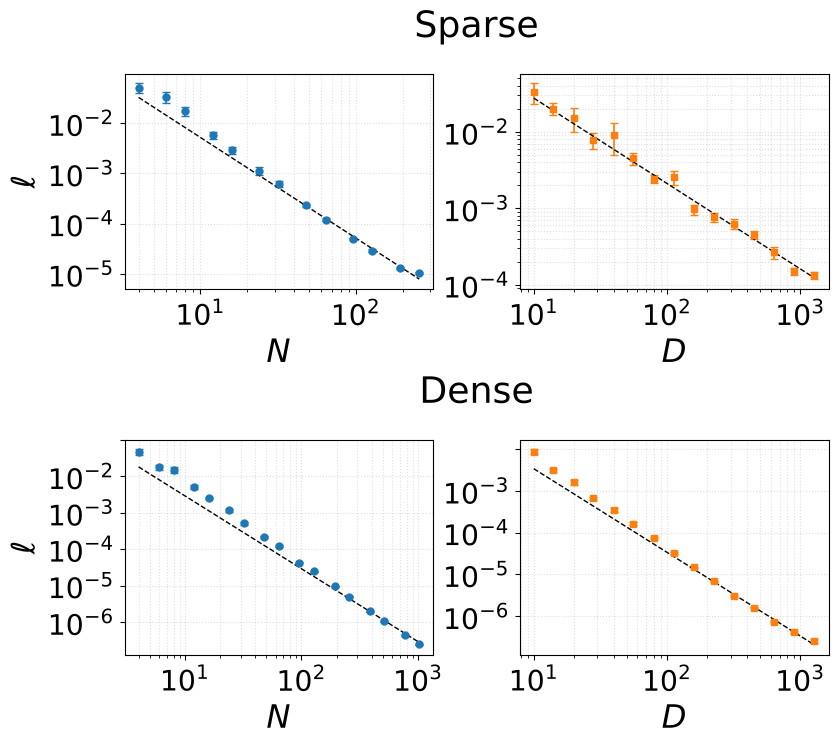

Joint shared exponent (Sparse N, Dense N, Dense D): α = 1.249
Independent Sparse D-sweep:                          α = 1.104


Figure saved to: figures/FigureA2.pdf


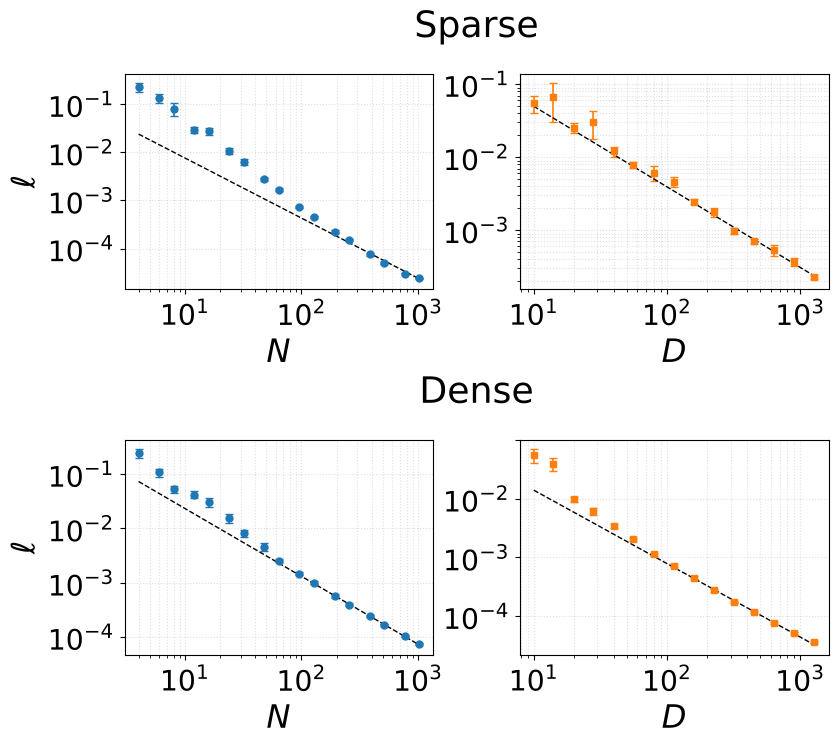

In [ ]:
def plot_scaling_fits_shared_v2(results, tail_fit=6, drop_N=None,
                                  cap_N_sparse=None, save_path=None,
                                  hide_yticklabels=None):
    """
    Four-panel figure (Sparse top, Dense bottom; N-sweep left, D-sweep right).
    Three panels (Sparse N, Dense N, Dense D) share a single jointly fitted
    exponent. Sparse D-sweep uses its own independent fit.

    Parameters
    ----------
    drop_N : dict[str, list[int]], optional
        N values to drop from the corresponding dataset's N-sweep before
        fitting/plotting. Useful for excluding numerical outliers.
        E.g. {"sparse": [384]}.
    cap_N_sparse : int, optional
        If set, restrict the Sparse N-sweep fit (and plot) to N <= cap.
        Used to avoid the saturation regime in the linear-sparse case.
    """
    drop_N = drop_N or {}

    res_g = results["gaussian_powerlaw"]
    res_s = results["sparse"]

    def get_arrays(res, key, drops=None, cap=None):
        drops = drops or []
        keys = sorted(res[key].keys())
        keys = [k for k in keys if k not in drops]
        if cap is not None:
            keys = [k for k in keys if k <= cap]
        means = np.array([res[key][k][0] for k in keys])
        sems  = np.array([res[key][k][1] for k in keys])
        return np.array(keys, dtype=float), means, sems

    # Sparse: drop and possibly cap
    Ns_s, Ns_means, Ns_sems = get_arrays(res_s, "N",
                                           drops=drop_N.get("sparse", []),
                                           cap=cap_N_sparse)
    Ds_s, Ds_means, Ds_sems = get_arrays(res_s, "D")

    # Dense: drop only (no cap)
    Ns_g, Ng_means, Ng_sems = get_arrays(res_g, "N",
                                           drops=drop_N.get("gaussian_powerlaw", []))
    Ds_g, Dg_means, Dg_sems = get_arrays(res_g, "D")

    # Joint shared fit on tails: 3 sweeps (Sparse N, Dense N, Dense D)
    Ns_g_t = Ns_g[-tail_fit:]; Ng_means_t = Ng_means[-tail_fit:]
    Ds_g_t = Ds_g[-tail_fit:]; Dg_means_t = Dg_means[-tail_fit:]
    Ns_s_t = Ns_s[-tail_fit:]; Ns_means_t = Ns_means[-tail_fit:]

    n1 = len(Ns_g_t); n2 = len(Ds_g_t); n3 = len(Ns_s_t)
    A = np.zeros((n1 + n2 + n3, 4))
    A[:n1, 0] = np.log(Ns_g_t);    A[:n1, 1] = 1.0
    A[n1:n1+n2, 0] = np.log(Ds_g_t); A[n1:n1+n2, 2] = 1.0
    A[n1+n2:, 0] = np.log(Ns_s_t); A[n1+n2:, 3] = 1.0
    b = np.concatenate([np.log(Ng_means_t),
                        np.log(Dg_means_t),
                        np.log(Ns_means_t)])

    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    slope_shared, ic_gN, ic_gD, ic_sN = coeffs
    a_shared = -float(slope_shared)

    # Independent fit for sparse D-sweep
    aD_s_indep, ic_sD = fit_powerlaw(Ds_s, Ds_means, tail=tail_fit)

    print(f"Joint shared exponent (Sparse N, Dense N, Dense D): α = {a_shared:.3f}")
    print(f"Independent Sparse D-sweep:                          α = {aD_s_indep:.3f}")

    # Plot
    fig, axes = plt.subplots(2, 2, figsize=(8, 7), constrained_layout=False)
    fig.subplots_adjust(left=0.09, right=0.97, top=0.92, bottom=0.09,
                         wspace=0.28, hspace=0.7)

    # Sparse N (top-left): shared
    ax = axes[0, 0]
    ax.errorbar(Ns_s, Ns_means, yerr=Ns_sems, fmt="o", capsize=3,
                color="C0", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ns_s, np.exp(ic_sN) * Ns_s ** -a_shared,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$N$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # Sparse D (top-right): independent
    ax = axes[0, 1]
    ax.errorbar(Ds_s, Ds_means, yerr=Ds_sems, fmt="s", capsize=3,
                color="C1", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ds_s, np.exp(ic_sD) * Ds_s ** -aD_s_indep,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$D$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # Dense N (bottom-left): shared
    ax = axes[1, 0]
    ax.errorbar(Ns_g, Ng_means, yerr=Ng_sems, fmt="o", capsize=3,
                color="C0", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ns_g, np.exp(ic_gN) * Ns_g ** -a_shared,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$N$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # Dense D (bottom-right): shared
    ax = axes[1, 1]
    ax.errorbar(Ds_g, Dg_means, yerr=Dg_sems, fmt="s", capsize=3,
                color="C1", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ds_g, np.exp(ic_gD) * Ds_g ** -a_shared,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$D$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # The right-hand panels share the loss axis with the left-hand ones
    axes[0, 1].set_ylabel(""); axes[1, 1].set_ylabel("")
    # One labelled tick per decade on every axis, as in the original
    for a in axes.flat:
        a.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=20))
        a.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=20))
    # Drop a crowded top tick label in selected panels: {(row, col): [values]}
    for (r_, c_), vals in (hide_yticklabels or {}).items():
        _f = ticker.LogFormatterSciNotation()
        axes[r_, c_].yaxis.set_major_formatter(ticker.FuncFormatter(
            lambda v, p, _f=_f, _h=vals: '' if any(abs(np.log10(v) - np.log10(h)) < 1e-9 for h in _h) else _f(v, p)))

    # Row labels
    for row, label in enumerate(["Sparse", "Dense"]):
        bbox_left = axes[row, 0].get_position()
        bbox_right = axes[row, 1].get_position()
        x_center = (bbox_left.x0 + bbox_right.x1) / 2
        y_top = bbox_left.y1 + 0.04
        fig.text(x_center, y_top, label, ha="center", va="bottom", fontsize=FA_ROW)

    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
        print(f"Figure saved to: {save_path}")
    plt.show()
    return fig


# Figure A1: linear features. Drop the numerical outlier N=384; cap the sparse N-sweep at 256.
figA1 = plot_scaling_fits_shared_v2(
    results_linear, tail_fit=6, drop_N={"sparse": [384]}, cap_N_sparse=256,
    hide_yticklabels={(1, 0): [1e-1], (1, 1): [1e-2]},
    save_path="../figures/FigureA1.pdf",
)
figA1.savefig("../figures/FigureA1.png", dpi=300, bbox_inches="tight")

# Figure A2: ReLU features, no drops or caps.
figA2 = plot_scaling_fits_shared_v2(
    results_relu, tail_fit=6, drop_N=None, cap_N_sparse=None,
    hide_yticklabels={(1, 1): [1e-1]},
    save_path="../figures/FigureA2.pdf",
)
figA2.savefig("../figures/FigureA2.png", dpi=300, bbox_inches="tight")


## Experiment code (original, for reference; not re-run here)

The cells below are the original Colab notebook that produced the archived results: setup (mounts Google Drive), data samplers, model and closed-form solver, sweeps, driver, spot check, the two runs (one A100, about 4 hours) and the save step, followed by the post-processing used to choose the fit window. They are not executed here.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_DIR = '/content/drive/MyDrive/sparse_scaling_laws/'
os.makedirs(DRIVE_DIR, exist_ok=True)
print(f"Saving to: {DRIVE_DIR}")

import math
import time
import pickle
from datetime import datetime
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from dataclasses import dataclass
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_dtype(torch.float32)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Match figure styling used in other paper figures
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
})

print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

@dataclass
class Config:
    alpha1: float = 1.0
    alpha2: float = 0.3
    M: int = 10_000
    n_test: int = 50_000
    n_seeds: int = 20

In [ ]:
def sample_sparse(n, cfg: Config):
    """Sparse Bernoulli x heavy-tailed amplitude."""
    j = torch.arange(1, cfg.M + 1, device=device, dtype=torch.float32)
    p = j.pow(-(cfg.alpha1 + 1.0))
    amp = j.pow(-(cfg.alpha2 + 1.0) / 2.0)
    mask = (torch.rand(n, cfg.M, device=device) < p)
    signs = torch.where(
        torch.rand(n, cfg.M, device=device) < 0.5,
        torch.tensor(-1.0, dtype=torch.float32, device=device),
        torch.tensor(1.0, dtype=torch.float32, device=device),
    )
    X = mask.float() * signs * amp
    return X.to(torch.float32)

def sample_gaussian_powerlaw(n, cfg: Config):
    """Dense baseline, matched tail exponent."""
    alpha = cfg.alpha1 + cfg.alpha2 + 1.0
    j = torch.arange(1, cfg.M + 1, device=device, dtype=torch.float32)
    std = j.pow(-(alpha + 1.0) / 2.0)
    X = torch.randn(n, cfg.M, device=device, dtype=torch.float32) * std
    return X

def make_teacher(cfg: Config, generator=None):
    return torch.randn(cfg.M, device=device, dtype=torch.float32, generator=generator)

In [ ]:
class TwoLayerNet(nn.Module):
    def __init__(self, N, M, activation="linear"):
        super().__init__()
        u = torch.randn(N, M, dtype=torch.float32) / math.sqrt(N)
        self.u = nn.Parameter(u, requires_grad=False)
        self.theta = nn.Parameter(torch.zeros(N, dtype=torch.float32))
        self.activation = activation

    def forward(self, x):
        h = x @ self.u.T
        if self.activation == "relu":
            h = torch.relu(h)
        return h @ self.theta


def train_and_eval_pinv(N, D, cfg: Config, data_sampler, seed: int,
                          activation="linear"):
    """Closed-form min-norm interpolator. Returns (test_mse, train_mse)."""
    g = torch.Generator(device=device).manual_seed(seed)
    w = make_teacher(cfg, generator=g)

    X_train = data_sampler(D, cfg)
    y_train = X_train @ w
    X_test = data_sampler(cfg.n_test, cfg)
    y_test = X_test @ w

    model = TwoLayerNet(N, cfg.M, activation).to(device)

    with torch.no_grad():
        h_train = X_train @ model.u.T
        h_test = X_test @ model.u.T
        if activation == "relu":
            h_train = torch.relu(h_train)
            h_test = torch.relu(h_test)
        Phi_train = h_train.double()
        Phi_test = h_test.double()
        y64_train = y_train.double()
        y64_test = y_test.double()

        # CPU pinv for LAPACK SVD stability
        theta_star = torch.linalg.pinv(Phi_train.cpu(), rtol=1e-10) @ y64_train.cpu()

        train_pred = Phi_train.cpu() @ theta_star
        test_pred = Phi_test.cpu() @ theta_star
        train_mse = ((train_pred - y64_train.cpu()) ** 2).mean().item()
        test_mse = ((test_pred - y64_test.cpu()) ** 2).mean().item()

    return test_mse, train_mse

In [ ]:
def fit_powerlaw(xs, ys, tail=None):
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if tail is not None:
        xs, ys = xs[-tail:], ys[-tail:]
    lx, ly = np.log(xs), np.log(ys)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coeffs, *_ = np.linalg.lstsq(A, ly, rcond=None)
    return -float(coeffs[0]), float(coeffs[1])


def sweep_N(N_list, D_fixed, cfg, data_sampler, activation, desc=""):
    out, diagnostics = {}, {}
    pbar = tqdm(N_list, desc=f"{desc} [{activation}] N-sweep", leave=True)
    for N in pbar:
        losses, train_losses = [], []
        for s in range(cfg.n_seeds):
            tmse, trmse = train_and_eval_pinv(N, D_fixed, cfg, data_sampler,
                                                seed=s, activation=activation)
            losses.append(tmse); train_losses.append(trmse)
            pbar.set_postfix(N=N, seed=f"{s+1}/{cfg.n_seeds}",
                             test=f"{np.mean(losses):.2e}",
                             train=f"{np.mean(train_losses):.1e}")
        out[N] = (float(np.mean(losses)),
                   float(np.std(losses) / np.sqrt(len(losses))))
        diagnostics[N] = dict(train_loss=float(np.mean(train_losses)))
    return out, diagnostics


def sweep_D(D_list, N_fixed, cfg, data_sampler, activation, desc=""):
    out, diagnostics = {}, {}
    pbar = tqdm(D_list, desc=f"{desc} [{activation}] D-sweep", leave=True)
    for D in pbar:
        losses, train_losses = [], []
        for s in range(cfg.n_seeds):
            tmse, trmse = train_and_eval_pinv(N_fixed, D, cfg, data_sampler,
                                                seed=s, activation=activation)
            losses.append(tmse); train_losses.append(trmse)
            pbar.set_postfix(D=D, seed=f"{s+1}/{cfg.n_seeds}",
                             test=f"{np.mean(losses):.2e}",
                             train=f"{np.mean(train_losses):.1e}")
        out[D] = (float(np.mean(losses)),
                   float(np.std(losses) / np.sqrt(len(losses))))
        diagnostics[D] = dict(train_loss=float(np.mean(train_losses)))
    return out, diagnostics


def plot_scaling_fits(results, tail_fit=6, save_path=None):
    """
    Four-panel figure (Sparse top, Dense bottom; N-sweep left, D-sweep right).
    Empirical points with error bars + black dashed asymptotic-fit line
    extended across the whole panel. Row labels above each row.
    """
    fig, axes = plt.subplots(2, 2, figsize=(8, 7), constrained_layout=False)
    fig.subplots_adjust(left=0.09, right=0.97, top=0.92, bottom=0.09,
                         wspace=0.28, hspace=0.55)

    dataset_names = ["sparse", "gaussian_powerlaw"]
    row_labels = ["Sparse", "Dense"]

    for row, ds_name in enumerate(dataset_names):
        res = results[ds_name]

        # N-sweep
        ax = axes[row, 0]
        Ns = np.array(sorted(res["N"].keys()), dtype=float)
        means = np.array([res["N"][int(N)][0] for N in Ns])
        sems = np.array([res["N"][int(N)][1] for N in Ns])
        ax.errorbar(Ns, means, yerr=sems, fmt="o", capsize=3,
                    color="C0", markersize=5, linewidth=1, elinewidth=1.2)
        aN_fit, intercept_N = fit_powerlaw(Ns, means, tail=tail_fit)
        ax.plot(Ns, np.exp(intercept_N) * Ns ** -aN_fit,
                color="black", linestyle="--", linewidth=1.0)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(r"$N$"); ax.set_ylabel(r"$\ell$")
        ax.grid(True, which="both", ls=":", alpha=0.4)

        # D-sweep
        ax = axes[row, 1]
        Ds = np.array(sorted(res["D"].keys()), dtype=float)
        means = np.array([res["D"][int(D)][0] for D in Ds])
        sems = np.array([res["D"][int(D)][1] for D in Ds])
        ax.errorbar(Ds, means, yerr=sems, fmt="s", capsize=3,
                    color="C1", markersize=5, linewidth=1, elinewidth=1.2)
        aD_fit, intercept_D = fit_powerlaw(Ds, means, tail=tail_fit)
        ax.plot(Ds, np.exp(intercept_D) * Ds ** -aD_fit,
                color="black", linestyle="--", linewidth=1.0)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(r"$D$"); ax.set_ylabel(r"$\ell$")
        ax.grid(True, which="both", ls=":", alpha=0.4)

    # Row labels above each row
    for row, label in enumerate(row_labels):
        bbox_left = axes[row, 0].get_position()
        bbox_right = axes[row, 1].get_position()
        x_center = (bbox_left.x0 + bbox_right.x1) / 2
        y_top = bbox_left.y1 + 0.04
        fig.text(x_center, y_top, label, ha="center", va="bottom", fontsize=14)

    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
        print(f"Figure saved to: {save_path}")
    plt.show()
    return fig

In [ ]:
def run_experiment_pinv(cfg: Config, activation: str, save_prefix=""):
    results = {}
    N_list = [4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768, 1024]
    D_list = [10, 14, 20, 28, 40, 56, 80, 112, 160, 224, 320, 448, 640, 896, 1280]
    D_for_N_sweep = 50_000
    N_for_D_sweep = 16_000

    datasets = [("sparse", sample_sparse),
                ("gaussian_powerlaw", sample_gaussian_powerlaw)]

    t0 = time.time()
    for name, sampler in tqdm(datasets, desc=f"datasets [{activation}]", position=0):
        N_results, N_diag = sweep_N(N_list, D_for_N_sweep, cfg, sampler,
                                     activation, desc=name)
        D_results, D_diag = sweep_D(D_list, N_for_D_sweep, cfg, sampler,
                                     activation, desc=name)

        alpha_N, _ = fit_powerlaw(list(N_results.keys()),
                                  [v[0] for v in N_results.values()], tail=6)
        alpha_D, _ = fit_powerlaw(list(D_results.keys()),
                                  [v[0] for v in D_results.values()], tail=6)

        tqdm.write(f"\n[{activation}][{name}] alpha_N = {alpha_N:.3f}, alpha_D = {alpha_D:.3f}")
        results[name] = dict(N=N_results, D=D_results,
                             alpha_N=alpha_N, alpha_D=alpha_D,
                             N_diag=N_diag, D_diag=D_diag)

        # Per-dataset Drive checkpoint
        ts = datetime.now().strftime("%Y%m%d_%H%M%S")
        path = os.path.join(DRIVE_DIR,
                              f"checkpoint_{save_prefix}{activation}_{name}_{ts}.pkl")
        with open(path, "wb") as f:
            pickle.dump({"results": results, "config": cfg, "activation": activation}, f)
        print(f"  Checkpoint saved: {path}", flush=True)

    a1, a2 = cfg.alpha1, cfg.alpha2
    tqdm.write(f"\n=== Linear theory (reference) ===")
    tqdm.write(f"Sparse:   alpha_N = {a1+a2+1:.3f}, alpha_D = {(a1+a2+1)/(a1+1):.3f}")
    tqdm.write(f"Gaussian: alpha_N = alpha_D = {a1+a2+1:.3f}")
    tqdm.write(f"\ntotal time: {time.time()-t0:.1f}s")
    return results

In [ ]:
print("=" * 60)
print("Spot check: linear features, sparse N=256, D=50000, seed=0")
print("=" * 60)
t0 = time.time()
test_mse, train_mse = train_and_eval_pinv(N=256, D=50_000, cfg=Config(),
                                           data_sampler=sample_sparse,
                                           seed=0, activation="linear")
print(f"  test = {test_mse:.3e}, train = {train_mse:.3e}")
print(f"  elapsed: {time.time()-t0:.1f}s")
print()

print("=" * 60)
print("Spot check: ReLU features, sparse N=256, D=50000, seed=0")
print("=" * 60)
t0 = time.time()
test_mse, train_mse = train_and_eval_pinv(N=256, D=50_000, cfg=Config(),
                                           data_sampler=sample_sparse,
                                           seed=0, activation="relu")
print(f"  test = {test_mse:.3e}, train = {train_mse:.3e}")
print(f"  elapsed: {time.time()-t0:.1f}s")

In [ ]:
results_linear = run_experiment_pinv(Config(), activation="linear")

In [ ]:
results_relu = run_experiment_pinv(Config(), activation="relu")

In [ ]:
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
save_path = os.path.join(DRIVE_DIR, f"results_pinv_linear_and_relu_{ts}.pkl")
with open(save_path, "wb") as f:
    pickle.dump({
        "results_linear": results_linear,
        "results_relu": results_relu,
        "config": Config(),
        "timestamp": ts,
    }, f)
print(f"Saved to {save_path}")

In [ ]:
import numpy as np
import copy
import pickle, os
from datetime import datetime

def fit_powerlaw(xs, ys, tail=None):
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if tail is not None:
        xs, ys = xs[-tail:], ys[-tail:]
    lx, ly = np.log(xs), np.log(ys)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coeffs, *_ = np.linalg.lstsq(A, ly, rcond=None)
    return -float(coeffs[0]), float(coeffs[1])


def drop_outliers_and_refit(results, N_to_drop_per_dataset, tail=6):
    """Drop specified N values from each dataset's N-sweep and refit."""
    new_results = {}
    for ds in results:
        drops = N_to_drop_per_dataset.get(ds, [])
        N_filt = {N: v for N, v in results[ds]["N"].items() if N not in drops}
        Ns = sorted(N_filt.keys())
        means_N = [N_filt[N][0] for N in Ns]
        aN, _ = fit_powerlaw(Ns, means_N, tail=tail)

        Ds = sorted(results[ds]["D"].keys())
        means_D = [results[ds]["D"][D][0] for D in Ds]
        aD, _ = fit_powerlaw(Ds, means_D, tail=tail)

        new_results[ds] = {
            "N": N_filt,
            "D": copy.deepcopy(results[ds]["D"]),
            "alpha_N": aN,
            "alpha_D": aD,
            "N_diag": {k: v for k, v in results[ds].get("N_diag", {}).items() if k not in drops},
            "D_diag": copy.deepcopy(results[ds].get("D_diag", {})),
        }
    return new_results


# Drop only N=384 from sparse linear; everything else clean
results_linear_clean = drop_outliers_and_refit(
    results_linear,
    {"sparse": [384], "gaussian_powerlaw": []},
    tail=6,
)

# ReLU has no outliers — no drops needed, but rerun through to get consistent format
results_relu_clean = drop_outliers_and_refit(
    results_relu,
    {"sparse": [], "gaussian_powerlaw": []},
    tail=6,
)

print("="*72)
print("Cleaned exponents")
print("="*72)
print(f"\n{'config':>30}  {'αN':>8}  {'αD':>8}  {'αN/αD':>8}")
for activation, res in [('linear', results_linear_clean), ('relu', results_relu_clean)]:
    for ds in ['sparse', 'gaussian_powerlaw']:
        aN = res[ds]['alpha_N']
        aD = res[ds]['alpha_D']
        print(f"{activation:>10} {ds:>20}  {aN:>8.3f}  {aD:>8.3f}  {aN/aD:>8.3f}")

print("\n=== Linear theory ===")
print("Sparse:   αN = 2.30, αD = 1.15  →  αN/αD = 2.00")
print("Gaussian: αN = αD = 2.30        →  αN/αD = 1.00")

# Save the CLEANED results
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
save_path = os.path.join(DRIVE_DIR, f"results_pinv_CLEANED_{ts}.pkl")
with open(save_path, "wb") as f:
    pickle.dump({
        "results_linear": results_linear_clean,
        "results_relu": results_relu_clean,
        "config": Config(),
        "timestamp": ts,
        "note": "Cleaned: dropped N=384 from linear sparse N-sweep due to numerical outlier",
    }, f)
print(f"\nSaved cleaned results to {save_path}")

In [ ]:
import numpy as np

def fit_powerlaw(xs, ys, tail=None):
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if tail is not None:
        xs, ys = xs[-tail:], ys[-tail:]
    lx, ly = np.log(xs), np.log(ys)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coeffs, *_ = np.linalg.lstsq(A, ly, rcond=None)
    return -float(coeffs[0]), float(coeffs[1])

# Restrict to N <= 256 for linear sparse
Ns_full = sorted(results_linear['sparse']['N'].keys())
means_full = [results_linear['sparse']['N'][N][0] for N in Ns_full]

# Test different fit windows on N <= 256
Ns_cap = [N for N in Ns_full if N <= 256]
means_cap = [results_linear['sparse']['N'][N][0] for N in Ns_cap]
print(f"N values used for fit: {Ns_cap}")
for tail in [4, 5, 6, 7, len(Ns_cap)]:
    aN, _ = fit_powerlaw(Ns_cap, means_cap, tail=tail)
    print(f"  tail={tail}: αN = {aN:.3f}")